# Emotion Classification with RNNs, LSTMs & **GRUs**

Classifying text into 6 emotions (sadness, joy, love, anger, fear, surprise) by comparing plain recurrent models before building an Advanced Bidirectional GRU.**bold text**

**Import Libraries ->**
Import TensorFlowKeras, HuggingFace Datasets and evaluation tools.


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#dataset load karwane ma help karega

from datasets import load_dataset

**1. Import Libraries->**Load the dair-ai/emotion dataset from Hugging Face. https://huggingface.co/datasets/dair-ai/emotion

In [2]:
emotion_dataset = load_dataset('dair-ai/emotion')
train_text = emotion_dataset['train']['text']
train_label     = emotion_dataset['train']['label']

test_text       = emotion_dataset['test']['text']
test_label      = emotion_dataset['test']['label']

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [5]:
label_names = emotion_dataset['train'].features['label'].names

In [6]:
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [7]:
df_train = pd.DataFrame(
    {
        'text': train_text,
        'label': [label_names[i]for i in train_label]
    }
)

df_test = pd.DataFrame(
    {
        'text': test_text,
        'label': [label_names[i]for i in test_label]
    }
)

In [8]:
emotion_dataset['test'].features['label'].names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [9]:
for i in train_label: #i ->0
  print(label_names[i]) #label_names[0]

Streaming output truncated to the last 5000 lines.
sadness
sadness
anger
fear
love
joy
anger
sadness
sadness
joy
fear
joy
fear
love
love
anger
anger
sadness
fear
sadness
sadness
surprise
love
joy
joy
love
sadness
joy
joy
fear
sadness
anger
anger
sadness
love
fear
fear
anger
anger
joy
sadness
sadness
joy
joy
fear
sadness
joy
love
fear
anger
sadness
joy
anger
surprise
fear
joy
joy
love
fear
sadness
joy
anger
fear
anger
sadness
sadness
sadness
anger
sadness
fear
joy
anger
anger
sadness
fear
joy
anger
fear
sadness
joy
fear
joy
love
anger
fear
fear
fear
fear
joy
anger
anger
sadness
joy
sadness
joy
sadness
sadness
joy
sadness
fear
fear
joy
sadness
joy
sadness
joy
fear
anger
sadness
joy
anger
joy
joy
sadness
joy
joy
anger
anger
joy
joy
joy
sadness
joy
joy
joy
anger
anger
joy
love
joy
love
joy
joy
joy
sadness
joy
sadness
surprise
sadness
anger
anger
anger
fear
fear
joy
fear
fear
joy
anger
joy
joy
joy
love
joy
fear
sadness
sadness
surprise
sadness
sadness
anger
joy
love
fear
joy
anger
joy
surpr

In [10]:
df_train.isnull().sum()

,0
text,0
label,0


**3. Exploratory Data Analysis (EDA)**

Visualize class distribution across the 6 emotion labels.

In [11]:
df_train['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='object', name='label')

<Axes: xlabel='label', ylabel='count'>

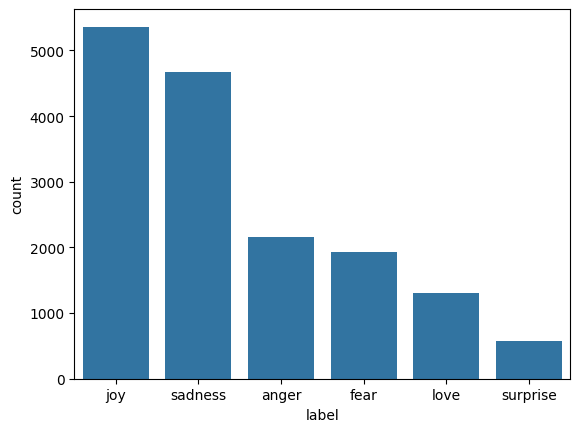

In [12]:
sns.countplot(x='label', data=df_train, order=df_train['label'].value_counts().index)

In [13]:
df_train

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


**4. Data Preprocessing - Using NLP**

Tokenize text, pad sequences to max length 50, and convert labels to NumPy arrays.

In [14]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words = 10000

tokenizer = Tokenizer(num_words=max_words, oov_token='')
tokenizer.fit_on_texts(df_train['text'])

train_sequence = tokenizer.texts_to_sequences(df_train['text'])
test_sequenece = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequence = pad_sequences(train_sequence,maxlen=50,padding='post', truncating='post')
padded_test_sequence = pad_sequences(test_sequenece ,maxlen=50,padding='post', truncating='post')

train_labels = np.array(train_label)
test_labels  = np.array(test_label)

num_classes = len(np.unique(train_labels))
num_classes


print(f"Vocabulary Size: {len(tokenizer.word_index)}")
print(f"Max Sentence Length: {padded_train_sequence.shape[1]}")

Vocabulary Size: 15213
Max Sentence Length: 50


**5. Shared Training Utilities**

Compute balanced class weights to handle dataset skew and setup early stopping.

In [16]:
from sklearn.utils import class_weight #find class weights manually

class_weights = class_weight.compute_class_weight(
       class_weight ='balanced',
       classes = np.unique(train_labels),
       y = train_labels
)

class_weight_dict = dict(enumerate(class_weights))

In [17]:
from tensorflow.keras.callbacks import EarlyStopping  #when the loss is not decreased and make minor(negligible) decrease they stop the model training

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

***6. Phase 1 — Plain Foundational Models***

Train plain (non-bidirectional) Simple RNN, Standard LSTM, and Standard GRU models.

***6.1 Model 1 — Simple RNN***

Plain unrolled Recurrent Neural Network.

In [18]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout, LSTM, GRU

rnn_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    SimpleRNN(units=128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

rnn_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [19]:
rnn_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequence, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 30s 51ms/step - accuracy: 0.1615 - loss: 2.0444 - val_accuracy: 0.0335 - val_loss: 1.8889
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 24s 48ms/step - accuracy: 0.1503 - loss: 1.8765 - val_accuracy: 0.0335 - val_loss: 1.7931
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 42s 49ms/step - accuracy: 0.1369 - loss: 1.8297 - val_accuracy: 0.1370 - val_loss: 1.7793
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 50ms/step - accuracy: 0.1426 - loss: 1.8102 - val_accuracy: 0.1650 - val_loss: 1.8005
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 24s 48ms/step - accuracy: 0.1513 - loss: 1.8032 - val_accuracy: 0.0475 - val_loss: 1.7994
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 50ms/step - accuracy: 0.1299 - loss: 1.8012 - val_accuracy: 0.1115 - val_loss: 1.7552
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 50ms/step - accuracy: 0.1367 - loss: 1.8029 - val_accuracy: 0.0875 - val_loss: 1.8205
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 26s 52ms/step - accuracy: 0.1326 - loss: 1.8023 - 

***6.2 Model 2 — Standard LSTM***

Plain stacked Long Short-Term Memory network.

In [20]:
lstm_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequence, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 72s 135ms/step - accuracy: 0.1665 - loss: 1.7945 - val_accuracy: 0.0335 - val_loss: 1.7986
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 64s 128ms/step - accuracy: 0.1643 - loss: 1.7938 - val_accuracy: 0.0330 - val_loss: 1.8100
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 84s 133ms/step - accuracy: 0.1454 - loss: 1.7933 - val_accuracy: 0.0875 - val_loss: 1.7903
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 65s 130ms/step - accuracy: 0.1831 - loss: 1.7873 - val_accuracy: 0.1785 - val_loss: 1.7945
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 86s 138ms/step - accuracy: 0.2242 - loss: 1.7057 - val_accuracy: 0.2185 - val_loss: 1.6625
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 137ms/step - accuracy: 0.3198 - loss: 1.4595 - val_accuracy: 0.4630 - val_loss: 1.3942
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 71s 142ms/step - accuracy: 0.5641 - loss: 1.0162 - val_accuracy: 0.6965 - val_loss: 0.9201
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 75s 129ms/step - accuracy: 0.7106 - loss: 0

***6.3 Model 3 — Standard GRU***

Plain stacked Gated Recurrent Unit network.

In [21]:
gru_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequence, test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 60s 112ms/step - accuracy: 0.1471 - loss: 1.7958 - val_accuracy: 0.1375 - val_loss: 1.7732
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 55s 110ms/step - accuracy: 0.1655 - loss: 1.7956 - val_accuracy: 0.2845 - val_loss: 1.7950
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 111ms/step - accuracy: 0.1530 - loss: 1.7938 - val_accuracy: 0.2880 - val_loss: 1.7700
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 84s 114ms/step - accuracy: 0.1529 - loss: 1.7910 - val_accuracy: 0.3280 - val_loss: 1.7842
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 55s 111ms/step - accuracy: 0.1818 - loss: 1.7761 - val_accuracy: 0.2015 - val_loss: 1.7821
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.1375 - loss: 1.7732
GRU Loss: 1.7732268571853638
GRU Accuracy: 0.13750000298023224


***6.4 Phase 1 Ranking & Selection***

Rank foundational models to pick the best base cell for Phase 2.

In [22]:
result_df = pd.DataFrame({
    'Model' : ['RNN', 'LSTM', 'GRU'],
    'Test Loss': [rnn_loss, lstm_loss, gru_loss],
    'Test Accuracy': [rnn_accuracy, lstm_accuracy, gru_accuracy]
    }).sort_values(by='Test Accuracy',ascending=False)
result_df

,Model,Test Loss,Test Accuracy
1,LSTM,0.508405,0.8660
2,GRU,1.773227,0.1375
0,RNN,1.755168,0.1115


***7. Phase 2 — Advanced Bidirectional GRU***

Enhance GRU with Bidirectional layers, 300D embeddings, and 0.5 dropout regularization.

*7.1 Model 4 — Advanced Stacked Bidirectional GRU

In [23]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(input_dim = max_words, output_dim = 300 , input_length = 50),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax') #Output Layer
    #Why i used num_classes in output layer and what will i get from this.
])

BiGRU.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

BiGRU.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

***Train & Evaluate Advanced Bidirectional GRU***

In [24]:
BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 173s 331ms/step - accuracy: 0.5745 - loss: 1.0354 - val_accuracy: 0.8880 - val_loss: 0.3621
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 159s 318ms/step - accuracy: 0.9178 - loss: 0.2294 - val_accuracy: 0.9195 - val_loss: 0.2318
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 151s 302ms/step - accuracy: 0.9441 - loss: 0.1556 - val_accuracy: 0.9025 - val_loss: 0.2772
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 152s 304ms/step - accuracy: 0.9577 - loss: 0.1127 - val_accuracy: 0.9205 - val_loss: 0.2496
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 201s 302ms/step - accuracy: 0.9712 - loss: 0.0813 - val_accuracy: 0.9240 - val_loss: 0.2396
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 203s 305ms/step - accuracy: 0.9728 - loss: 0.0720 - val_accuracy: 0.9160 - val_loss: 0.2962
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 151s 301ms/step - accuracy: 0.9793 - loss: 0.0602 - val_accuracy: 0.9215 - val_loss: 0.3030


In [25]:
BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(padded_test_sequence, test_labels)
print(f"BiGRU Loss: {BiGRU_loss}")
print(f"BiGRU Accuracy: {BiGRU_accuracy}")


63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 147ms/step - accuracy: 0.9195 - loss: 0.2318
BiGRU Loss: 0.23176096379756927
BiGRU Accuracy: 0.9194999933242798


***8. Overall Evaluation & Bias Analysis***

In [26]:
# sadness=5%,joy=14%,anger=67%,love=9%,suprise=50%,fear=2%

63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 159ms/step


<Axes: >

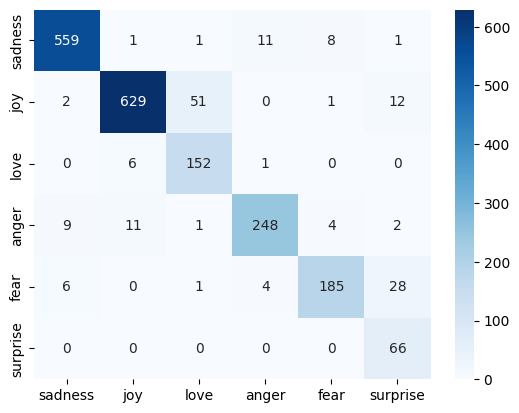

In [27]:
from sklearn.metrics import confusion_matrix

BiGRU_predictions = np.argmax(BiGRU.predict(padded_test_sequence),axis=1)

sns.heatmap(confusion_matrix(test_label, BiGRU_predictions),annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)
#


***9. Final Predictions***

Test the winning model on unseen sample sentences.

In [28]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: surprise
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


***10. Save Model & Tokenizer***

Export trained model and tokenizer artifacts for API deployment.

In [29]:
import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True) #yeh folder hai jiske andar sari exported file aane wali hai

#Save our BiGRU Model
BiGRU.save(os.path.join(model_dir, 'BiGRU_Modle.keras'))

#Save the tokenizer model
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
  pickle.dump(tokenizer, file)